# Lambda & Higher-Order Functions

In Python, functions are **objects**. You can store them in variables, pass them to other functions and return them from functions. A **higher-order function** takes a function as an argument or returns one. A **lambda** is a small function without a name.

**After this lesson you can:**

1. Write lambda expressions.
2. Use `sorted`, `min`, `max` with a `key` function.
3. Use `map`, `filter`, `functools.reduce` and `functools.partial`.
4. Compose small functions into a processing pipeline.

## 1. Functions Are Objects; Lambdas

```python
lambda arguments: expression
```

A lambda contains one expression and returns its value. Use lambdas for short functions that you pass to another function. For anything longer, use `def`.

In [1]:
def shout(text: str) -> str:
    return text.upper() + "!"

speak = shout                         # assign the function object to another name
print(speak("hello"), "|", shout.__name__, "|", type(shout).__name__)

square = lambda x: x * x
print("square(7) =", square(7))

operations = {"add": lambda a, b: a + b, "sub": lambda a, b: a - b, "mul": lambda a, b: a * b}
print({name: op(6, 3) for name, op in operations.items()})

HELLO! | shout | function
square(7) = 49
{'add': 9, 'sub': 3, 'mul': 18}


## 2. `key` Functions for Sorting and Selection

`sorted()`, `min()`, `max()` and `list.sort()` take a `key` function. Python calls the key once for each element and compares the results.

In [2]:
employees = [
    {"name": "Deniz", "dept": "Data", "salary": 72_000, "years": 3},
    {"name": "Ece", "dept": "Platform", "salary": 81_000, "years": 6},
    {"name": "Kaan", "dept": "Data", "salary": 65_000, "years": 1},
    {"name": "Selin", "dept": "Platform", "salary": 81_000, "years": 2},
]

by_salary = sorted(employees, key=lambda e: e["salary"], reverse=True)
print("by salary     :", [e["name"] for e in by_salary])

by_dept_then_salary = sorted(employees, key=lambda e: (e["dept"], -e["salary"]))
print("dept, salary  :", [(e["dept"], e["name"]) for e in by_dept_then_salary])

print("most senior   :", max(employees, key=lambda e: e["years"])["name"])

from operator import itemgetter
print("itemgetter    :", [e["name"] for e in sorted(employees, key=itemgetter("years"))])

by salary     : ['Ece', 'Selin', 'Deniz', 'Kaan']
dept, salary  : [('Data', 'Deniz'), ('Data', 'Kaan'), ('Platform', 'Ece'), ('Platform', 'Selin')]
most senior   : Ece
itemgetter    : ['Kaan', 'Selin', 'Deniz', 'Ece']


A tuple key sorts by several fields: first by department, then by salary (the minus sign gives descending salary). `operator.itemgetter` is a fast, readable alternative to simple lambdas.

## 3. `map`, `filter`, `reduce`, `partial`

| Function | Does | Comprehension equivalent |
| :--- | :--- | :--- |
| `map(f, items)` | apply `f` to every item | `[f(x) for x in items]` |
| `filter(pred, items)` | keep items where `pred(x)` is true | `[x for x in items if pred(x)]` |
| `functools.reduce(f, items)` | combine items into one value | a loop with an accumulator |
| `functools.partial(f, a)` | new function with some arguments fixed | — |

In [3]:
from functools import partial, reduce

prices = [120, 45, 300, 80]
print("map    :", list(map(lambda p: p * 1.2, prices)))
print("filter :", list(filter(lambda p: p >= 100, prices)))
print("reduce :", reduce(lambda acc, p: acc + p, prices, 0))

def apply_discount(price: float, rate: float) -> float:
    return round(price * (1 - rate), 2)

black_friday = partial(apply_discount, rate=0.30)       # fix one argument
print("partial:", [black_friday(p) for p in prices])

map    : [144.0, 54.0, 360.0, 96.0]
filter : [120, 300]
reduce : 545
partial: [84.0, 31.5, 210.0, 56.0]


## 4. Functions That Return Functions

A function can build and return a new function. The returned function remembers the variables of its creator (a **closure**). `compose()` below joins several functions into one pipeline: the output of each function is the input of the next one.

In [4]:
def compose(*functions):
    """compose(f, g, h)(x) == h(g(f(x)))"""
    return lambda x: reduce(lambda value, fn: fn(value), functions, x)

def clip(low, high):
    return lambda x: max(low, min(high, x))

def scale(factor):
    return lambda x: x * factor

clean = compose(abs, clip(0, 100), scale(0.01))
print([clean(v) for v in (-50, 20, 250, 75)])

[0.5, 0.2, 1.0, 0.75]


## 5. A Signal-Processing Pipeline

Higher-order functions are a natural fit for data pipelines: each step is a small function, and the pipeline is a list of steps. The example cleans a noisy sensor signal (synthetic data) in three steps and plots each stage.

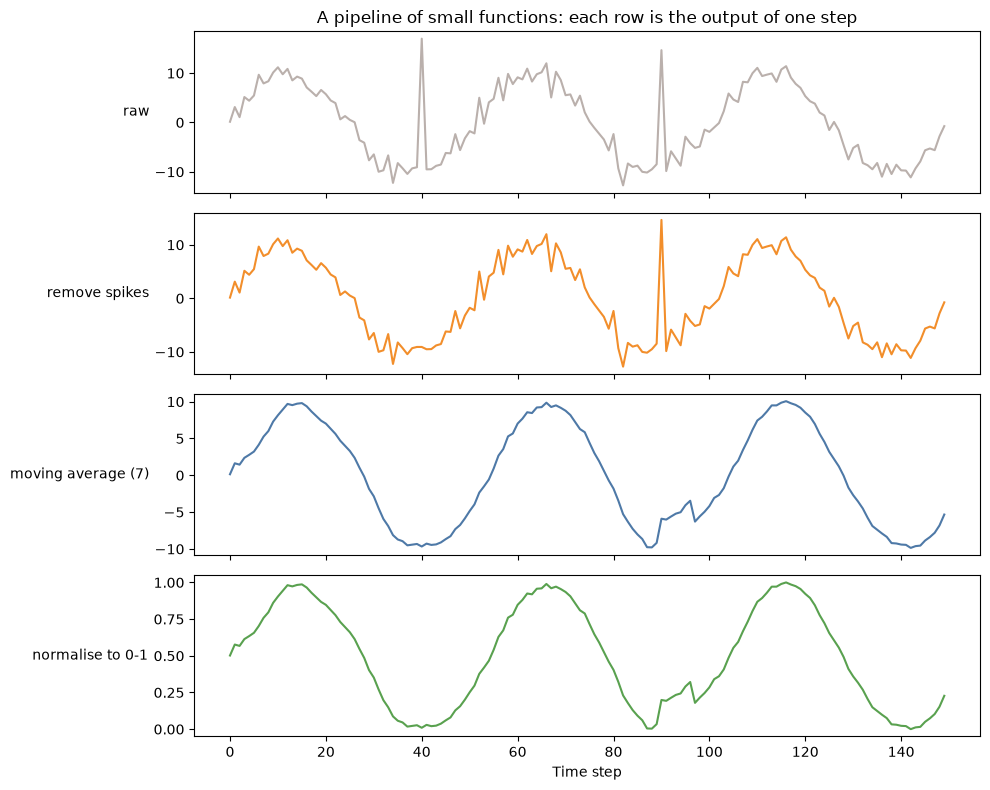

In [5]:
import math
import random

import matplotlib.pyplot as plt

random.seed(3)
raw = [10 * math.sin(t / 8) + random.gauss(0, 1.5) + (25 if t in (40, 90) else 0) for t in range(150)]

def remove_spikes(signal, limit=15):
    return [x if abs(x) < limit else (signal[i - 1] if i else 0) for i, x in enumerate(signal)]

def moving_average(window):
    def smooth(signal):
        return [sum(signal[max(0, i - window + 1):i + 1]) / len(signal[max(0, i - window + 1):i + 1])
                for i in range(len(signal))]
    return smooth

def normalise(signal):
    lo, hi = min(signal), max(signal)
    return [(x - lo) / (hi - lo) for x in signal]

steps = [("remove spikes", remove_spikes), ("moving average (7)", moving_average(7)), ("normalise to 0-1", normalise)]
stages = [("raw", raw)]
for name, fn in steps:
    stages.append((name, fn(stages[-1][1])))

fig, axes = plt.subplots(len(stages), 1, figsize=(10, 8), sharex=True)
for ax, (name, sig), color in zip(axes, stages, ["#BAB0AC", "#F28E2B", "#4E79A7", "#59A14F"]):
    ax.plot(sig, color=color, lw=1.5)
    ax.set_ylabel(name, rotation=0, ha="right", va="center")
axes[0].set_title("A pipeline of small functions: each row is the output of one step")
axes[-1].set_xlabel("Time step")
plt.tight_layout()
plt.show()

*Insight: Pass behaviour as a function instead of writing many similar functions. A `key=` argument, a list of pipeline steps or a callback keeps the general code fixed and moves the variable part into a small, testable function.*

## Real-World Use Case or Analogy

A higher-order function is like a **power drill with replaceable bits**. The drill (the general function) stays the same; you insert a different bit (the function argument) for wood, metal or screws.

The same idea appears across the course: scikit-learn pipelines are lists of transformation steps (M10), pandas `apply` and `groupby().agg()` take functions (M08), FastAPI registers your function as a request handler (M30), and agent frameworks call your Python functions as tools (M29).